# Projet d'Actuariat IMAFA 2026-2027
## Logiciel d'Assurance de Risque Météorologique
**Polytech Nice Sophia (MAM - IMAFA)**  
**Enseignant :** Marius AKRE  
**Auteurs :** Amiel Metier, Tahitoa Senis, Nicolas Muratore, Lucas Diguet, Gabriel Ferré  

---

### Objectifs de la démonstration :
1. **Modélisation Actuarielle** : Formaliser l'impact économique de la pluie journalière ($CA_t^{pl}$, $R_t^{pl}$, seuil $pl^*$).
2. **Département Tarification (Pricing)** : Calculer la prime pure $\mathbb{E}[I]$, l'écart-type $\sigma(I)$ des indemnités annuelles et la prime commerciale sur l'historique météo réel.
3. **Département Commercial (Devis)** : Émettre la proposition tarifaire et le devis contractuel.
4. **Département R&D (Analyse Rétrospective)** : Valider l'assurance sur l'exemple du sujet (Nice 1998) puis rejouer le contrat sur 25 années (ratio sinistres / primes).

In [1]:
import os
import sys
import numpy as np
import pandas as pd

# Ajout de la racine du projet au PYTHONPATH
sys.path.insert(0, os.path.abspath(".."))

from src.simulation import ClientProfile, compute_daily_impact, simulate_year
from src.pricing import price_contract_historical, split_into_coverage_periods
from src.weather_api import get_coordinates, fetch_historical_precipitation
from src.backtesting import run_retrospective_analysis, run_multi_year_backtest
from src.pdf_generator import generate_devis_pdf, make_quote_ref
from src.formatting import fmt_eur, fmt_pct
from src.bias_correction import find_calibration, correct_dataframe

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Définition du Profil Client (Section I)

On définit le commerçant type du sujet (ex: restaurant/café à Nice) :
- $CA = 1\,000$ € (Chiffre d'affaires journalier maximum par temps sec)
- $Cf = 400$ € (Coûts fixes journaliers incompressibles)
- $\overline{pl} = 10$ mm (Niveau de pluie pivot entraînant l'arrêt complet de l'activité, $CA = 0$)

Le seuil de rentabilité journalier est donné par :
$$pl^* = \overline{pl} \left(1 - \frac{Cf}{CA}\right)$$

In [2]:
profile = ClientProfile(
    ca_max=1000.0,
    cf=400.0,
    pl_pivot=10.0,
    city="Nice",
    subscription_date="1998-01-01"
)

seuil_perte = profile.pl_pivot * (1.0 - profile.cf / profile.ca_max)
print(f"Client : {profile.city}")
print(f"Seuil de perte journalière (pl*) : {seuil_perte:.2f} mm/jour")
print(f"-> Au-delà de {seuil_perte:.2f} mm de pluie, le résultat d'exploitation journalier devient négatif et l'assurance indemnise.")

Client : Nice
Seuil de perte journalière (pl*) : 6.00 mm/jour
-> Au-delà de 6.00 mm de pluie, le résultat d'exploitation journalier devient négatif et l'assurance indemnise.


## 2. Données Météorologiques Réelles (Nice)

Interrogation des coordonnées géographiques et récupération des précipitations journalières réelles pour Nice en 1998.

Comme dans l'application, la pluie de réanalyse est **corrigée par quantiles** sur la station au sol la plus proche (guide, section 5) : la réanalyse compte trop de jours de bruine et gonflerait la prime d'environ 13 %.

In [3]:
coords = get_coordinates(profile.city)
lat, lon, station = coords
print(f"Point de grille météo : {station} (lat={lat:.3f}, lon={lon:.3f})")
calibration = find_calibration(profile.city, lat, lon)
# Comme dans l'application : correction appliquée seulement si elle est recommandée pour cette ville
calibration = calibration if calibration and calibration["recommended"] else None
print(f"Correction calée sur la station : {calibration['station_name']} ({calibration['distance_km']} km, GHCN {calibration['station_id']})" if calibration else "Pluie non corrigée")

df_1998 = correct_dataframe(fetch_historical_precipitation(lat, lon, "1998-01-01", "1998-12-31"), calibration)
print(f"Nombre de jours relevés en 1998 : {len(df_1998)}")
print(f"Cumul pluviométrique annuel     : {df_1998['precipitation'].sum():.1f} mm")
print(f"Précipitation journalière max   : {df_1998['precipitation'].max():.1f} mm")

Point de grille météo : Nice, Région Provence-Alpes-Côte d'Azur, France (lat=43.703, lon=7.266)
Correction calée sur la station : Nice (7.6 km, GHCN FRE00104120)


Nombre de jours relevés en 1998 : 365
Cumul pluviométrique annuel     : 479.3 mm
Précipitation journalière max   : 48.8 mm


## 3. Simulation Journalière et Règle d'Indemnisation

L'assurance garantit un résultat journalier positif ou nul ($R_t \ge 0$).  
L'indemnité versée chaque jour de sinistre ($pl_t > pl^*$) est :
$$I_t = \max(0, -R_t^{pl})$$

In [4]:
sim_1998 = simulate_year(df_1998["precipitation"], profile)
sim_1998["date"] = df_1998["date"]

nb_jours_sinistres = (sim_1998["indemnity"] > 0).sum()
pertes_totales_1998 = sim_1998["indemnity"].sum()
res_non_assure = sim_1998["r_nass"].sum()
res_assure_brut = sim_1998["r_ass_brut"].sum()

print(f"Jours indemnisés sur l'année       : {nb_jours_sinistres} jours")
print(f"Résultat annuel non assuré (R_nass): {fmt_eur(res_non_assure)}")
print(f"Pertes réelles évitées (L)         : {fmt_eur(pertes_totales_1998)}")
print(f"Résultat annuel assuré brut (R_ass): {fmt_eur(res_assure_brut)}")

Jours indemnisés sur l'année       : 22 jours
Résultat annuel non assuré (R_nass): 188 902,36 €
Pertes réelles évitées (L)         : 7 707,62 €
Résultat annuel assuré brut (R_ass): 196 609,97 €


## 4. Tarification Prospective (Département Tarification)

Estimation de la prime sur un historique pluriannuel avec chargement de sécurité proportionnel à l'écart-type des indemnités ($P = \frac{E[I] + \beta\,\sigma(I)}{1 - \alpha}$) et frais de gestion.
Les années 1983 à 1997 sont connues au 1er janvier 1998 : la prime obtenue est donc celle que le logiciel aurait proposée **a priori** pour 1998.

In [5]:
# Simulation sur un dictionnaire d'années
df_hist = correct_dataframe(fetch_historical_precipitation(lat, lon, "1983-01-01", "1997-12-31"), calibration)
# Périodes de 365 jours commençant le 1er janvier (comme le contrat, même les années bissextiles)
periods = split_into_coverage_periods(df_hist, 1, 1, 1983, 1997)
hist_dict = {yr: p["precipitation"] for yr, p in periods.items()}

pricing_res = price_contract_historical(
    hist_dict,
    profile,
    safety_beta=0.30,
    expense_rate=0.15
)

print(f"Prime pure technique E[I]       : {fmt_eur(pricing_res['pure_premium'])}")
print(f"Écart-type des sinistres        : {fmt_eur(pricing_res['std_indemnity'])}")
print(f"Chargement de sécurité (β·σ)    : {fmt_eur(pricing_res['safety_loading'])}")
print(f"Prime commerciale annuelle      : {fmt_eur(pricing_res['commercial_premium'])}")

Prime pure technique E[I]       : 10 217,93 €
Écart-type des sinistres        : 2 053,47 €
Chargement de sécurité (β·σ)    : 616,04 €
Prime commerciale annuelle      : 12 745,85 €


## 4 bis. Devis (Département Commercial)

Le devis PDF est généré à partir du profil et du tarif ci-dessus, ici pour un client fictif.

In [6]:
devis = generate_devis_pdf(
    profile, pricing_res,
    station_label=station,
    history_label="1983 à 1997 (15 années)",
    client_name="Camille Exemple",
    company_name="SARL Glacier Exemple",
)
print(f"Devis {make_quote_ref(profile)} généré : {len(devis) / 1024:.0f} Ko, format PDF : {devis[:4] == b'%PDF'}")

Devis DEV-20261114-29B848 généré : 4 Ko, format PDF : True


## 5. Analyse Rétrospective — Exemple Nice 1998 (Département R&D)

Comme le demande le sujet, la prime $P_{1998}$ est **calculée a priori par le logiciel** (section 4, années 1983 à 1997), puis comparée aux résultats réellement observés en 1998 :
- Année : 1998 ($a$)
- Comparaison $R_{nass}$ vs $R_{ass}$ et $R_{net} = R_{ass} - P_{1998}$.

Les montants de l'exemple du sujet (90 000 €, 3 000 €, 5 000 €) sont illustratifs : avec la météo réelle, les chiffres diffèrent.

In [7]:
retro = run_retrospective_analysis(df_1998["precipitation"], profile, annual_premium=pricing_res["commercial_premium"])

print("=== BILAN RÉTROSPECTIF 1998 ===")
print(f"Résultat Non Assuré (R_nass)    : {fmt_eur(retro['r_nass'])}")
print(f"Prime a priori versée (P)       : {fmt_eur(retro['premium'])}")
print(f"Résultat Garanti Brut (R_ass)   : {fmt_eur(retro['r_ass'])}")
print(f"Pertes réelles évitées          : {fmt_eur(retro['pertes_evitees'])}")
print(f"Résultat Net Assuré (R_net)     : {fmt_eur(retro['r_net'])}")
print(f"Gain net grâce à l'assurance    : {fmt_eur(retro['gain_net_client'], signed=True)}")
print(f"Assurance favorable au client   : {'OUI' if retro['est_favorable'] else 'NON'}")

=== BILAN RÉTROSPECTIF 1998 ===
Résultat Non Assuré (R_nass)    : 188 902,36 €
Prime a priori versée (P)       : 12 745,85 €
Résultat Garanti Brut (R_ass)   : 196 609,97 €
Pertes réelles évitées          : 7 707,62 €
Résultat Net Assuré (R_net)     : 183 864,12 €
Gain net grâce à l'assurance    : -5 038,24 €
Assurance favorable au client   : NON


### Bilan rétrospectif 1998

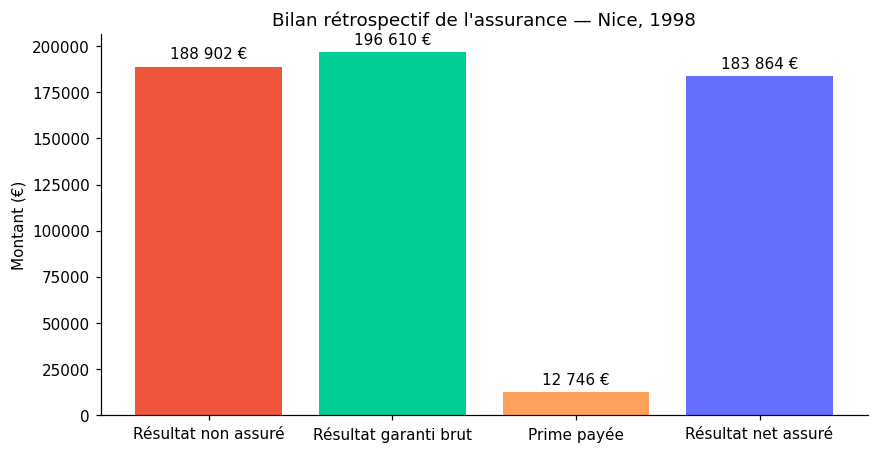

In [8]:
labels = ["Résultat non assuré", "Résultat garanti brut", "Prime payée", "Résultat net assuré"]
valeurs = [retro["r_nass"], retro["r_ass"], retro["premium"], retro["r_net"]]

fig, ax = plt.subplots(figsize=(9, 4.5))
barres = ax.bar(labels, valeurs, color=["#EF553B", "#00CC96", "#FFA15A", "#636EFA"])
ax.bar_label(barres, labels=[fmt_eur(v, 0) for v in valeurs], padding=3)
ax.set_ylabel("Montant (€)")
ax.set_title("Bilan rétrospectif de l'assurance — Nice, 1998")
plt.show()

### Trajectoire cumulée du résultat journalier

La prime est payée en une fois au 1er janvier : la courbe assurée démarre donc en dessous de zéro.

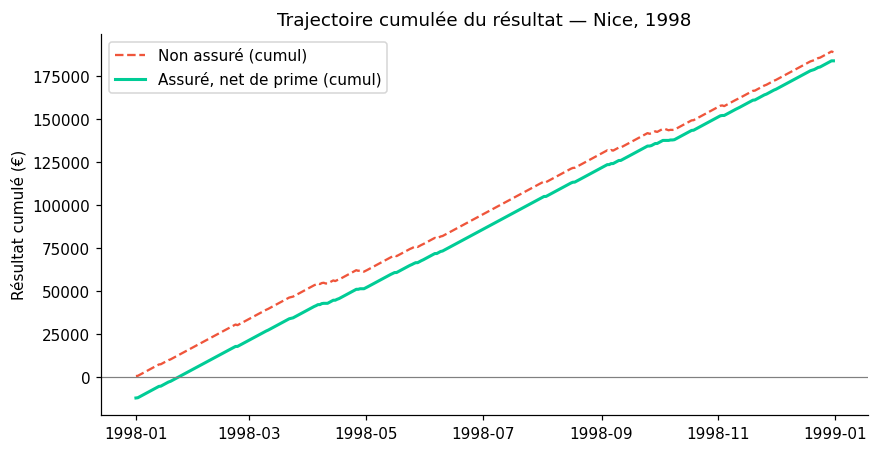

In [9]:
details = retro["details_journaliers"]
dates = df_1998["date"].values

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(dates, details["cum_r_nass"], "--", color="#EF553B", label="Non assuré (cumul)")
ax.plot(dates, details["cum_r_net"], color="#00CC96", linewidth=2, label="Assuré, net de prime (cumul)")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_ylabel("Résultat cumulé (€)")
ax.set_title("Trajectoire cumulée du résultat — Nice, 1998")
ax.legend()
plt.show()

## 6. Analyse rétrospective sur 25 années (Département R&D)

Chaque année $a$ de 2001 à 2025 est tarifée **a priori** (15 années précédentes, $\beta = 0{,}30$, frais 15 %), puis comparée aux indemnités réellement versées pendant $a$. Le **ratio sinistres / primes** (S/P) mesure la rentabilité du produit pour l'assureur ; la part des années favorables mesure son intérêt pour le client.

Années rejouées                 : 25
Ratio sinistres / primes (S/P)  : 79 %
Années favorables au client     : 36 %
Gain cumulé du client           : -70 047 €


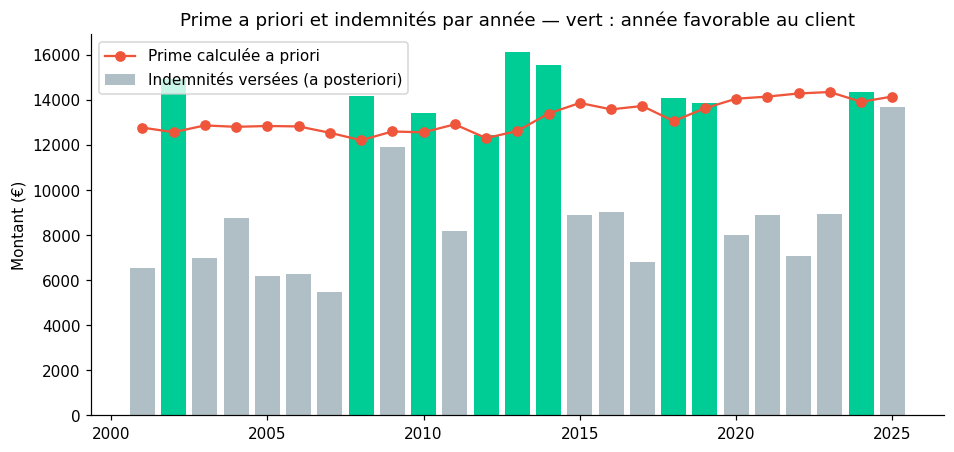

In [10]:
df_long = correct_dataframe(fetch_historical_precipitation(lat, lon, "1986-01-01", "2025-12-31"), calibration)
periodes = split_into_coverage_periods(df_long, 1, 1, 1986, 2025)
bt = run_multi_year_backtest(periodes, profile, list(range(2001, 2026)),
                             hist_years=15, safety_beta=0.30, expense_rate=0.15)
s, table = bt["summary"], bt["table"]

print(f"Années rejouées                 : {s['n_years']}")
print(f"Ratio sinistres / primes (S/P)  : {fmt_pct(s['loss_ratio'])}")
print(f"Années favorables au client     : {fmt_pct(s['share_favorable'])}")
print(f"Gain cumulé du client           : {fmt_eur(s['cumulative_client_gain'], 0)}")

fig, ax = plt.subplots(figsize=(10, 4.5))
couleurs = ["#00CC96" if f else "#B0BEC5" for f in table["favorable"]]
ax.bar(table["annee"], table["indemnites"], color=couleurs, label="Indemnités versées (a posteriori)")
ax.plot(table["annee"], table["prime"], "o-", color="#EF553B", label="Prime calculée a priori")
ax.set_ylabel("Montant (€)")
ax.set_title("Prime a priori et indemnités par année — vert : année favorable au client")
ax.legend()
plt.show()